In [52]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# 1. Buat dataset dummy
data = {
    'player_name': ['John', 'Alex', 'Michael', 'David', 'Chris', 'Ethan', 'James', 'Ryan', 'Daniel', 'Matthew', 
                    'Luke', 'Henry', 'Tom', 'Sam', 'Oliver', 'Liam', 'Benjamin', 'Mason', 'Jacob', 'Charlie'],
    'position': ['Forward', 'Midfielder', 'Defender', 'Midfielder', 'Forward', 'Goalkeeper', 'Forward', 
                 'Defender', 'Goalkeeper', 'Midfielder', 'Defender', 'Forward', 'Defender', 'Midfielder', 
                 'Forward', 'Goalkeeper', 'Defender', 'Forward', 'Midfielder', 'Defender'],
    'goals_scored': [5, 2, 0, 3, 7, 0, 6, 1, 0, 2, 0, 4, 1, 0, 5, 0, 0, 3, 1, 0],
    'assists': [3, 1, 2, 0, 5, 0, 3, 2, 0, 4, 0, 2, 1, 1, 3, 0, 2, 2, 3, 1],
    'passes_completed': [100, 80, 90, 70, 110, 50, 95, 75, 40, 85, 60, 95, 80, 65, 105, 55, 70, 80, 60, 50],
    'tackles': [10, 8, 5, 7, 12, 1, 9, 6, 2, 10, 5, 4, 6, 7, 8, 3, 5, 9, 4, 5],
    'minutes_played': [540, 450, 400, 600, 550, 300, 520, 330, 250, 470, 300, 520, 330, 600, 500, 250, 400, 450, 550, 300]
}

df = pd.DataFrame(data)

# Encode posisi menjadi numerik
df['position_encoded'] = df['position'].map({
    'Forward': 0,
    'Midfielder': 1,
    'Defender': 2,
    'Goalkeeper': 3
})

# 2. Tambahkan kolom total_statistics sebagai target
df['total_statistics'] = (df['goals_scored'] + 
                          df['assists'] + 
                          df['passes_completed']*0.01 +  # Normalisasi nilai yang lebih besar
                          df['tackles']*0.1 +            # Berikan bobot pada tackles
                          df['minutes_played']*0.001)    # Normalisasi nilai yang lebih besar

In [53]:
# 3. Pisahkan fitur dan target
X = df[['goals_scored', 'assists', 'passes_completed', 'tackles', 'minutes_played', 'position_encoded']]
y = df['total_statistics']

# Bagi data menjadi set pelatihan dan set pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [54]:
# 4. Latih model RandomForestRegressor
regressor = RandomForestRegressor(random_state=42)
regressor.fit(X_train, y_train)

# 5. Prediksi
y_pred = regressor.predict(X_test)

In [55]:
# Tambahkan prediksi total statistik ke dataframe
df['predicted_total_statistics'] = regressor.predict(X)

In [56]:
# 6

r2 = r2_score(y_test, y_pred)
print("R-squared (R²) Score:", r2)

R-squared (R²) Score: 0.9131200009837945


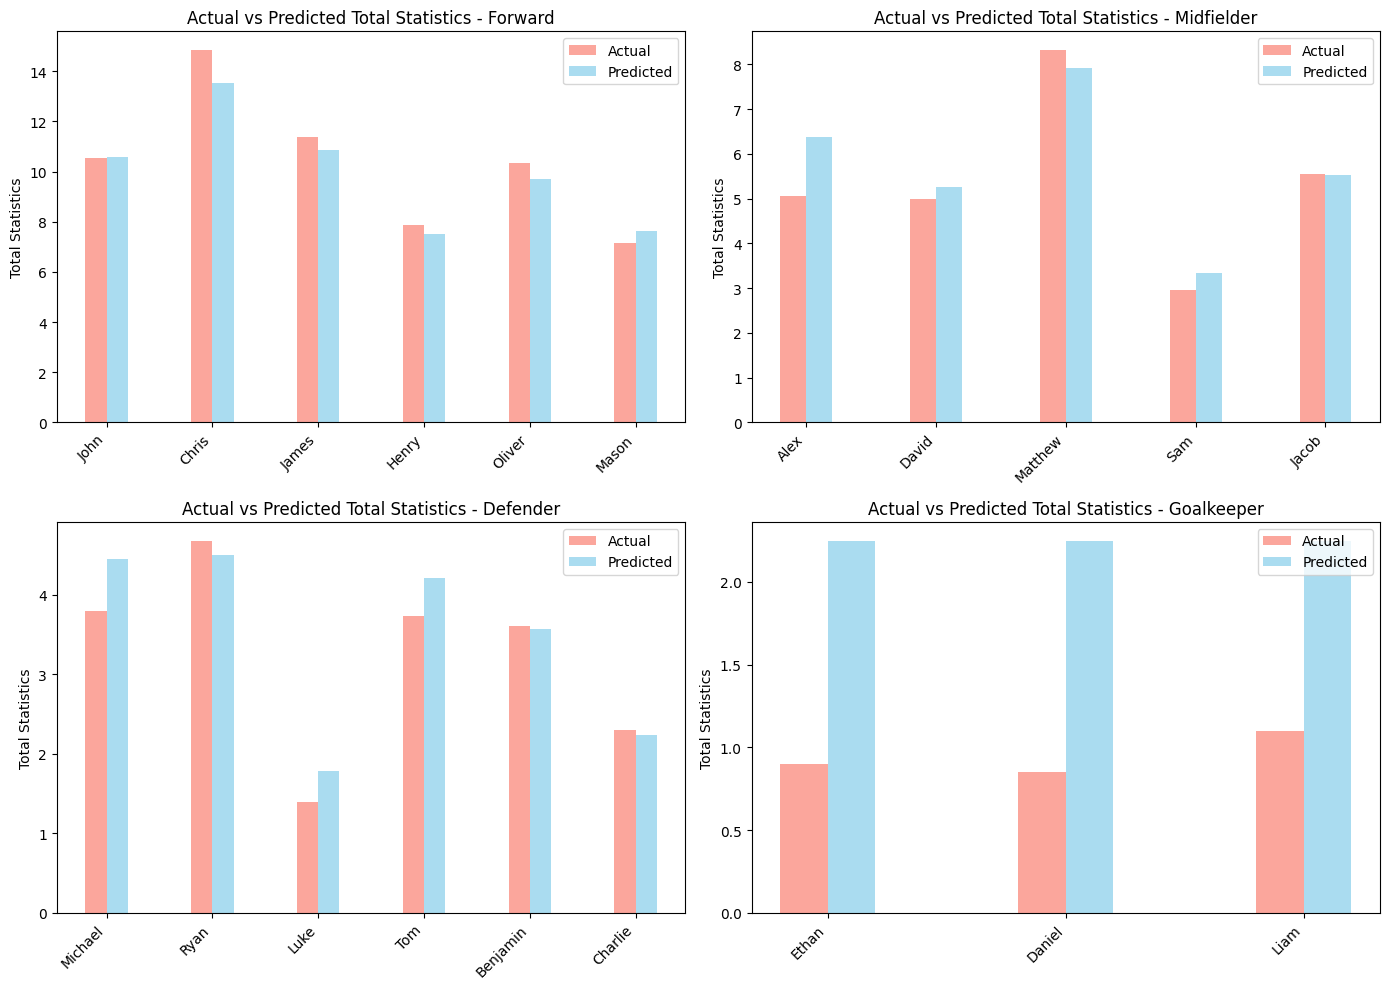

In [57]:
# Create a figure for the bar plots
unique_positions = df['position_encoded'].unique()
position_names = {0: 'Forward', 1: 'Midfielder', 2: 'Defender', 3: 'Goalkeeper'}

plt.figure(figsize=(14, 10))

bar_width = 0.2 

for i, position in enumerate(unique_positions):
    # Filter data for the current position
    position_df = df[df['position_encoded'] == position]
    
    # Create an index for each player's bars
    index = np.arange(len(position_df['player_name']))
    
    # Create bar plot
    plt.subplot(2, 2, i + 1)
    plt.bar(index, position_df['total_statistics'], width=bar_width, label='Actual', color='salmon', alpha=0.7)
    plt.bar(index + bar_width, position_df['predicted_total_statistics'], width=bar_width, label='Predicted', color='skyblue', alpha=0.7)

    # Labeling
    plt.title(f'Actual vs Predicted Total Statistics - {position_names[position]}')
    plt.ylabel('Total Statistics')
    plt.xticks(index + bar_width / 2, position_df['player_name'], rotation=45, ha='right')
    plt.legend()

plt.tight_layout()
plt.show()

In [59]:
df

,player_name,position,goals_scored,assists,passes_completed,tackles,minutes_played,position_encoded,total_statistics,predicted_total_statistics
0,John,Forward,5,3,100,10,540,0,10.54,10.5626
1,Alex,Midfielder,2,1,80,8,450,1,5.05,6.3674
2,Michael,Defender,0,2,90,5,400,2,3.80,4.4472
3,David,Midfielder,3,0,70,7,600,1,5.00,5.2502
4,Chris,Forward,7,5,110,12,550,0,14.85,13.5456
5,Ethan,Goalkeeper,0,0,50,1,300,3,0.90,2.2504
6,James,Forward,6,3,95,9,520,0,11.37,10.8542
7,Ryan,Defender,1,2,75,6,330,2,4.68,4.4981
8,Daniel,Goalkeeper,0,0,40,2,250,3,0.85,2.2504
9,Matthew,Midfielder,2,4,85,10,470,1,8.32,7.9103


In [58]:
# 7. Rekomendasikan formasi
def recommend_formation(df, n_defenders=4, n_midfielders=3, n_forwards=3):
    forwards = df[df['position'] == 'Forward'].sort_values(by='predicted_total_statistics', ascending=False).head(n_forwards)
    midfielders = df[df['position'] == 'Midfielder'].sort_values(by='predicted_total_statistics', ascending=False).head(n_midfielders)
    defenders = df[df['position'] == 'Defender'].sort_values(by='predicted_total_statistics', ascending=False).head(n_defenders)
    goalkeeper = df[df['position'] == 'Goalkeeper'].sort_values(by='predicted_total_statistics', ascending=False).head(1)
    
    team = pd.concat([goalkeeper, defenders, midfielders, forwards])
    return team

# Tentukan formasi 4-3-3
best_team = recommend_formation(df)

best_team[["player_name", "position"]]

,player_name,position
5,Ethan,Goalkeeper
7,Ryan,Defender
2,Michael,Defender
12,Tom,Defender
16,Benjamin,Defender
9,Matthew,Midfielder
1,Alex,Midfielder
18,Jacob,Midfielder
4,Chris,Forward
6,James,Forward
